# HW：50 Startups 多元線性回歸（CRISP-DM + sklearn）

依照 CRISP-DM 六步驟：Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Deployment。

## 1. Business Understanding
- **目標**：以 R&D Spend、Administration、Marketing Spend、State 預測新創公司的 Profit。
- **利害關係人**：投資人、經營者，想知道哪一項支出最影響獲利。
- **成功標準**：測試集 R² 高（> 0.9）、MAE / RMSE 低，並找出最精簡且有效的特徵組合。

In [1]:
import gzip, pickle, warnings
from io import StringIO
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import statsmodels.api as sm
import optuna
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
RANDOM_STATE = 0

/sessions/keen-stoic-hypatia/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Data Understanding
### Step 1：從網路載入資料（失敗時改讀本機 `50_Startups.csv`）

In [2]:
URL = 'https://raw.githubusercontent.com/Avik-Jain/100-Days-Of-ML-Code/master/datasets/50_Startups.csv'
try:
    r = requests.get(URL, timeout=10)
    r.raise_for_status()
    data = pd.read_csv(StringIO(r.text))
    print('Loaded from web:', URL)
except Exception as e:
    print('Web load failed -> use local file.', e)
    data = pd.read_csv('50_Startups.csv')

print(data.head())
print(data.columns)

Loaded from web: https://raw.githubusercontent.com/Avik-Jain/100-Days-Of-ML-Code/master/datasets/50_Startups.csv
   R&D Spend  Administration  Marketing Spend       State     Profit
0  165349.20       136897.80        471784.10    New York  192261.83
1  162597.70       151377.59        443898.53  California  191792.06
2  153441.51       101145.55        407934.54     Florida  191050.39
3  144372.41       118671.85        383199.62    New York  182901.99
4  142107.34        91391.77        366168.42     Florida  166187.94
Index(['R&D Spend', 'Administration', 'Marketing Spend', 'State', 'Profit'], dtype='object')


In [3]:
data.info()
print('\nMissing values:\n', data.isnull().sum())
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     object 
 4   Profit           50 non-null     float64
dtypes: float64(4), object(1)
memory usage: 2.1+ KB

Missing values:
 R&D Spend          0
Administration     0
Marketing Spend    0
State              0
Profit             0
dtype: int64


,R&D Spend,Administration,Marketing Spend,Profit
count,50.000000,50.000000,50.000000,50.000000
mean,73721.615600,121344.639600,211025.097800,112012.639200
std,45902.256482,28017.802755,122290.310726,40306.180338
min,0.000000,51283.140000,0.000000,14681.400000
25%,39936.370000,103730.875000,129300.132500,90138.902500
50%,73051.080000,122699.795000,212716.240000,107978.190000
75%,101602.800000,144842.180000,299469.085000,139765.977500
max,165349.200000,182645.560000,471784.100000,192261.830000


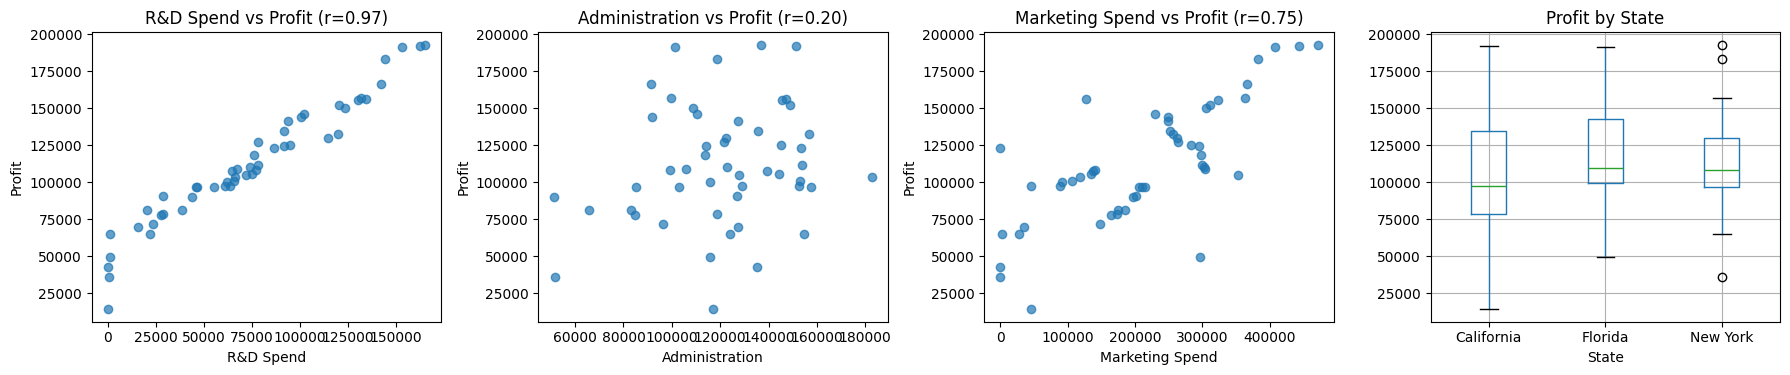

                 R&D Spend  Administration  Marketing Spend  Profit
R&D Spend            1.000           0.242            0.724   0.973
Administration       0.242           1.000           -0.032   0.201
Marketing Spend      0.724          -0.032            1.000   0.748
Profit               0.973           0.201            0.748   1.000


In [4]:
# 各特徵與 Profit 的散佈圖 + 相關係數
num_cols = ['R&D Spend', 'Administration', 'Marketing Spend']
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, num_cols):
    ax.scatter(data[c], data['Profit'], alpha=.7)
    ax.set_xlabel(c); ax.set_ylabel('Profit')
    ax.set_title(f'{c} vs Profit (r={data[c].corr(data["Profit"]):.2f})')
data.boxplot(column='Profit', by='State', ax=axes[3]); axes[3].set_title('Profit by State')
plt.suptitle(''); plt.tight_layout(); plt.show()
print(data[num_cols + ['Profit']].corr().round(3))

## 3. Data Preparation
### Step 2：One-hot encoding、處理 dummy variable trap、train/test split
- `State` 是 nominal 特徵 → `OneHotEncoder(drop='first')`，n 類只放 n-1 個 dummy，避免共線性。
- 數值欄位若有缺值以中位數補（此資料集無缺值，保留程式以防換資料集）。
- `train_test_split(test_size=0.2)`：用沒看過的資料評估，才能判斷 overfit。

In [5]:
data[num_cols] = data[num_cols].fillna(data[num_cols].median())
X = data.drop('Profit', axis=1)
y = data['Profit'].astype(float)

# 方法一：ColumnTransformer（建模 pipeline 用）
ct = ColumnTransformer([('state', OneHotEncoder(drop='first'), ['State'])], remainder='passthrough')

# 方法二：get_dummies（特徵選擇時保留欄位名稱）
X_enc = pd.get_dummies(X, columns=['State'], drop_first=True, dtype=float)
print(X_enc.head())

X_train, X_test, y_train, y_test = train_test_split(X_enc, y, test_size=0.2, random_state=RANDOM_STATE)
print('train:', X_train.shape, ' test:', X_test.shape)

   R&D Spend  Administration  Marketing Spend  State_Florida  State_New York
0  165349.20       136897.80        471784.10            0.0             1.0
1  162597.70       151377.59        443898.53            0.0             0.0
2  153441.51       101145.55        407934.54            1.0             0.0
3  144372.41       118671.85        383199.62            0.0             1.0
4  142107.34        91391.77        366168.42            1.0             0.0
train: (40, 5)  test: (10, 5)


## 4. Modeling
### Step 3：All-in 多元線性回歸

In [6]:
lr = LinearRegression().fit(X_train, y_train)
print('Intercept:', round(lr.intercept_, 2))
print(pd.Series(lr.coef_, index=X_enc.columns).round(4))

Intercept: 42554.17
R&D Spend            0.7735
Administration       0.0329
Marketing Spend      0.0366
State_Florida     -959.2842
State_New York     699.3691
dtype: float64


## 5. Evaluation
### Step 4：MSE / MAE / RMSE / R²

             train          test
R2    9.502000e-01  9.347000e-01
MAE   6.341536e+03  7.514294e+03
MSE   8.157100e+07  8.350286e+07
RMSE  9.031667e+03  9.137990e+03


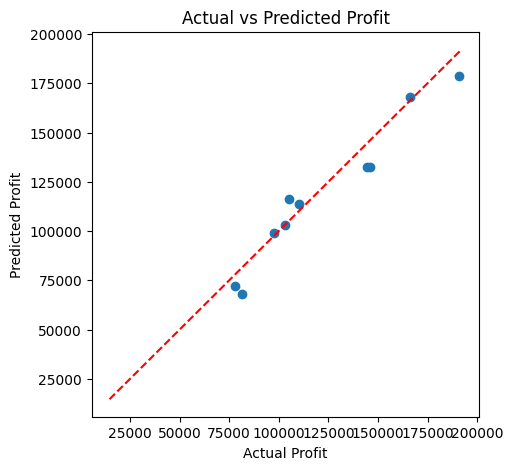

In [7]:
def evaluate(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'R2': r2_score(y_true, y_pred), 'MAE': mean_absolute_error(y_true, y_pred),
            'MSE': mse, 'RMSE': np.sqrt(mse)}

res_train = evaluate(y_train, lr.predict(X_train))
res_test = evaluate(y_test, lr.predict(X_test))
print(pd.DataFrame({'train': res_train, 'test': res_test}).round(4))

y_pred = lr.predict(X_test)
plt.figure(figsize=(5, 5))
plt.scatter(y_test, y_pred)
lim = [y.min(), y.max()]; plt.plot(lim, lim, 'r--')
plt.xlabel('Actual Profit'); plt.ylabel('Predicted Profit'); plt.title('Actual vs Predicted Profit')
plt.show()

- **R²**：模型解釋了多少比例的 Profit 變異，越接近 1 越好。
- **MAE**：平均絕對誤差，單位是美元，直觀。
- **MSE / RMSE**：平方誤差，對大誤差懲罰較重；RMSE 回到原單位。
- train 與 test 指標接近 → 沒有明顯 overfit；若 train 遠好於 test 則是 overfit。

### 4-1 特徵選擇：Backward elimination（p-value < 0.05）
用 statsmodels OLS 看每個係數的 p-value，每次移除最不顯著的特徵。

In [8]:
def backward_elimination(X, y, sl=0.05):
    cols = list(X.columns)
    while True:
        model = sm.OLS(y, sm.add_constant(X[cols])).fit()
        p = model.pvalues.drop('const')
        if p.max() <= sl:
            return cols, model
        print(f'remove {p.idxmax():<16} p = {p.max():.4f}')
        cols.remove(p.idxmax())

be_cols, be_model = backward_elimination(X_enc, y)
print('\nKept:', be_cols)
print(be_model.summary().tables[1])

remove State_New York   p = 0.9898
remove State_Florida    p = 0.9398
remove Administration   p = 0.6018
remove Marketing Spend  p = 0.0600

Kept: ['R&D Spend']
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       4.903e+04   2537.897     19.320      0.000    4.39e+04    5.41e+04
R&D Spend      0.8543      0.029     29.151      0.000       0.795       0.913


### 4-2 Forward selection：選 1～5 個特徵的 RMSE 與 R²

In [9]:
def forward_selection(X_train, X_test, y_train, y_test, max_features):
    selected, results = [], []
    for k in range(1, max_features + 1):
        best = None
        for f in X_train.columns.difference(selected):
            cols = selected + [f]
            m = LinearRegression().fit(X_train[cols], y_train)
            e = evaluate(y_test, m.predict(X_test[cols]))
            if best is None or e['RMSE'] < best[1]['RMSE']:
                best = (f, e)
        selected.append(best[0])
        results.append({'Number of Features': k, 'Selected Features': selected.copy(),
                        'RMSE': best[1]['RMSE'], 'R-squared': best[1]['R2']})
    return pd.DataFrame(results)

results_df = forward_selection(X_train, X_test, y_train, y_test, X_enc.shape[1])
print('Results Table:')
print(results_df)

Results Table:
   Number of Features                                  Selected Features  \
0                   1                                        [R&D Spend]   
1                   2                       [R&D Spend, Marketing Spend]   
2                   3       [R&D Spend, Marketing Spend, State_New York]   
3                   4  [R&D Spend, Marketing Spend, State_New York, S...   
4                   5  [R&D Spend, Marketing Spend, State_New York, S...   

          RMSE  R-squared  
0  8274.868018   0.946459  
1  8198.797191   0.947439  
2  8309.059683   0.946015  
3  8409.916714   0.944697  
4  9137.990153   0.934707  


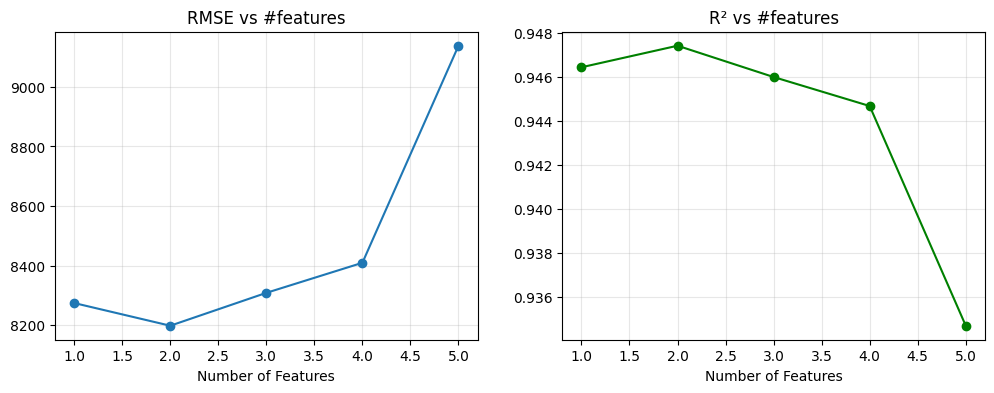

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(results_df['Number of Features'], results_df['RMSE'], 'o-'); ax[0].set_title('RMSE vs #features')
ax[1].plot(results_df['Number of Features'], results_df['R-squared'], 'o-', color='green'); ax[1].set_title('R² vs #features')
for a in ax: a.set_xlabel('Number of Features'); a.grid(alpha=.3)
plt.show()

### 4-3 Lasso（L1）＋ SelectFromModel
Lasso 會把不重要特徵的係數壓成 0，等於自動做特徵選擇。

In [11]:
from sklearn.feature_selection import SelectFromModel
scaler = StandardScaler().fit(X_train)
lasso = Lasso(alpha=1000, max_iter=50000).fit(scaler.transform(X_train), y_train)
print(pd.Series(lasso.coef_, index=X_enc.columns).round(2))
sfm = SelectFromModel(lasso, prefit=True)
print('SelectFromModel keeps:', list(X_enc.columns[sfm.get_support()]))

R&D Spend          35849.78
Administration         0.00
Marketing Spend     3438.94
State_Florida         -0.00
State_New York         0.00
dtype: float64
SelectFromModel keeps: ['R&D Spend', 'Marketing Spend']


### 4-4 Overfit / Underfit：training vs test curve
以 forward selection 的順序增加特徵數，畫出 train 與 test 的 RMSE。

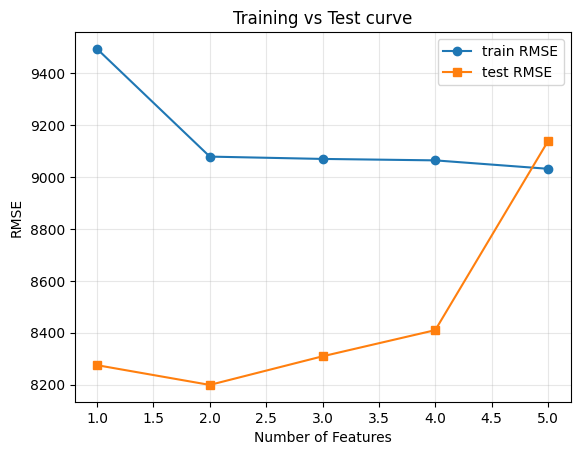

In [12]:
order = results_df['Selected Features'].iloc[-1]
tr, te = [], []
for k in range(1, len(order) + 1):
    m = LinearRegression().fit(X_train[order[:k]], y_train)
    tr.append(evaluate(y_train, m.predict(X_train[order[:k]]))['RMSE'])
    te.append(evaluate(y_test, m.predict(X_test[order[:k]]))['RMSE'])
plt.plot(range(1, len(order)+1), tr, 'o-', label='train RMSE')
plt.plot(range(1, len(order)+1), te, 's-', label='test RMSE')
plt.xlabel('Number of Features'); plt.ylabel('RMSE'); plt.legend(); plt.grid(alpha=.3)
plt.title('Training vs Test curve'); plt.show()

train RMSE 隨特徵增加持續下降，但 test RMSE 在 k=2 後回升：特徵越多越容易 overfit。結論與講義一致：R&D Spend 是最關鍵的特徵，加上 Marketing Spend 效果最好。

### 4-5 用 Optuna 優化模型（模型類型、alpha、特徵子集，以 5-fold CV RMSE 為目標）

In [13]:
features = list(X_enc.columns)

def objective(trial):
    cols = [f for f in features if trial.suggest_categorical(f'use_{f}', [True, False])]
    if not cols:
        return 1e12
    kind = trial.suggest_categorical('model', ['Linear', 'Ridge', 'Lasso'])
    if kind == 'Linear':
        reg = LinearRegression()
    else:
        alpha = trial.suggest_float('alpha', 1e-3, 1e3, log=True)
        reg = Ridge(alpha=alpha) if kind == 'Ridge' else Lasso(alpha=alpha, max_iter=50000)
    pipe = Pipeline([('sc', StandardScaler()), ('reg', reg)])
    s = cross_val_score(pipe, X_train[cols], y_train, cv=5, scoring='neg_root_mean_squared_error')
    return -s.mean()

study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=150)
print('Best CV RMSE:', round(study.best_value, 2))
print(study.best_params)

Best CV RMSE: 9756.53
{'use_R&D Spend': True, 'use_Administration': False, 'use_Marketing Spend': True, 'use_State_Florida': False, 'use_State_New York': False, 'model': 'Lasso', 'alpha': 0.5019960832277307}


In [14]:
bp = study.best_params
best_cols = [f for f in features if bp[f'use_{f}']]
reg = {'Linear': LinearRegression(),
       'Ridge': Ridge(alpha=bp.get('alpha', 1.0)),
       'Lasso': Lasso(alpha=bp.get('alpha', 1.0), max_iter=50000)}[bp['model']]
best_model = Pipeline([('sc', StandardScaler()), ('reg', reg)]).fit(X_train[best_cols], y_train)
print('Features:', best_cols)
print('Test metrics:', {k: round(v, 4) for k, v in evaluate(y_test, best_model.predict(X_test[best_cols])).items()})

Features: ['R&D Spend', 'Marketing Spend']
Test metrics: {'R2': 0.9474, 'MAE': 6886.3109, 'MSE': 67218662.9879, 'RMSE': np.float64(8198.6989)}


## 6. Deployment
### Step 5：pickle + gzip 儲存模型，再載入預測

In [15]:
bundle = {'model': best_model, 'features': best_cols}
with gzip.open('startup_model.pkl.gz', 'wb') as f:
    pickle.dump(bundle, f)

with gzip.open('startup_model.pkl.gz', 'rb') as f:
    loaded = pickle.load(f)

new = pd.DataFrame([{'R&D Spend': 120000, 'Administration': 130000, 'Marketing Spend': 300000,
                     'State_Florida': 0.0, 'State_New York': 1.0}])
print('Predicted profit: $%.2f' % loaded['model'].predict(new[loaded['features']])[0])

Predicted profit: $150753.57


- **監控**：新資料進來時定期重算 RMSE，若明顯上升就重新訓練。
- **文件**：資料來源、前處理、特徵與指標都記錄在本 notebook，網頁版放在 GitHub Pages。